# Seasonal Variation using Diffusion Interpolation — Temperature (Air)

This notebook visualizes the seasonal variation of **Temperature (Air)** using
the physics-based steady-state diffusion interpolation method.

Parameterized duplicate of `22_seasonal_variation_do.ipynb` for air temperature.
To adapt for another parameter, change the values in the **Parameters** cell below.

**Key optimizations (inherited from v3):**
- Grid resolution: 4000 m (vs 2000 m) — ~4× fewer cells
- Water mask: `shapely.prepared.prep` for vectorized spatial lookup
- Coordinate reprojection: `pyproj.Transformer` (vectorized, no GeoDataFrame)
- Station snapping: `scipy.spatial.cKDTree` (vectorized, no per-row loop)
- SOR solver: `max_iters=500`, `tol=1e-3`, `omega=1.8`
- Plotting: Pre-built `PatchCollection` for land (avoids repeated `draw_idle()`)

In [1]:
# --- 1. Imports ---
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import scipy.ndimage as ndimage
from scipy.spatial import cKDTree
from shapely.geometry import Point
from shapely.prepared import prep
from pyproj import Transformer
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
import sys
from pathlib import Path

project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

In [2]:
# ============================================================
# PARAMETERS — Change these to adapt for a different variable
# ============================================================

# --- Target variable ---
PARAMETER = 'temp'              # Column name in merged_gdf
PARAMETER_CONFIG_KEY = 'temperature'  # Key in MappingConfig.VARIABLE_SETTINGS
PARAMETER_DISPLAY_NAME = 'Temperature (Air)'  # Human-readable name for titles
DATA_FILE = 'yearly_temp_df.csv'  # Pre-computed CSV filename in each seasonal subset dir

# --- Seasonal / spatial selection ---
season = 'Summer'
layer = 'bottom'
target_year = '1991'

# --- Performance Tuning ---
GRID_RES = 4000    # Grid resolution in meters
MAX_ITERS = 500    # Max SOR iterations
TOL = 1e-3         # Convergence tolerance
OMEGA = 1.8        # SOR relaxation factor

## 3. Data Loading & Preprocessing

In [3]:
# 1. Load Custom Boundary Shapefiles (WGS84)
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water_boundary = gpd.read_file(water_boundary_path)
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_land_boundary = gpd.read_file(land_boundary_path)

if sis_water_boundary.crs != "EPSG:4326":
    sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

bounds = sis_water_boundary.total_bounds

# 2. Project water mask to UTM Zone 53N to define the computation grid
utm_crs = 'EPSG:32653'
sis_water_utm = sis_water_boundary.to_crs(utm_crs)
bounds_utm = sis_water_utm.total_bounds

# 3. Create grid (optimized resolution)
grid_x_1d = np.arange(bounds_utm[0], bounds_utm[2], GRID_RES)
grid_y_1d = np.arange(bounds_utm[1], bounds_utm[3], GRID_RES)
grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)
print(f'Grid shape: {grid_x.shape} ({grid_x.size} points)')

# 4. OPTIMIZED water mask: prepared geometry for fast spatial lookup
water_polygon = sis_water_utm.geometry.union_all()
prepared_poly = prep(water_polygon)
flat_x = grid_x.flatten()
flat_y = grid_y.flatten()
grid_points = [Point(x, y) for x, y in zip(flat_x, flat_y)]
valid_points_mask = np.array([prepared_poly.contains(pt) for pt in grid_points])
water_mask = valid_points_mask.reshape(grid_x.shape)
print(f'Water cells: {water_mask.sum()} / {water_mask.size}')

# 5. OPTIMIZED coordinate transform: pyproj Transformer (vectorized)
transformer = Transformer.from_crs(utm_crs, "EPSG:4326", always_xy=True)
lon_flat, lat_flat = transformer.transform(flat_x, flat_y)
lon_wgs = lon_flat.reshape(grid_x.shape)
lat_wgs = lat_flat.reshape(grid_y.shape)

# 6. Load station data
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
stations_gdf = merged_gdf[['zettaicode', 'longitude', 'latitude']].drop_duplicates().set_index('zettaicode')
stations_utm = gpd.GeoDataFrame(
    stations_gdf,
    geometry=[Point(xy) for xy in zip(stations_gdf.longitude, stations_gdf.latitude)],
    crs='EPSG:4326'
).to_crs(utm_crs)

# 7. Pre-compute SOR helper matrices (reused for every year)
kernel = np.array([[0, 1, 0],
                   [1, 0, 1],
                   [0, 1, 0]])
water_float = water_mask.astype(np.float64)
W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
valid_W_mask = W > 0

i_indices, j_indices = np.indices(grid_x.shape)
red_mask = (i_indices + j_indices) % 2 == 0
black_mask = ~red_mask

# 8. Build KDTree of water grid cells for fast station snapping
water_iy, water_ix = np.where(water_mask)
water_coords = np.column_stack([grid_x[water_iy, water_ix],
                                 grid_y[water_iy, water_ix]])
water_tree = cKDTree(water_coords)

Grid shape: (58, 116) (6728 points)
Water cells: 1588 / 6728


## 4. Optimized Diffusion Interpolation Solver

In [4]:
def run_diffusion_interpolation(year_data, stations_utm_local,
                                grid_x_1d, grid_y_1d,
                                water_mask, grid_x, grid_y,
                                max_iters=MAX_ITERS, tol=TOL, omega=OMEGA):
    """Optimized SOR diffusion solver with vectorized station snapping."""
    Z = np.full(water_mask.shape, np.nan)
    mean_val = year_data[PARAMETER].mean()
    Z[water_mask] = mean_val
    fixed_mask = np.zeros_like(water_mask, dtype=bool)

    # Vectorized station snapping via KDTree
    common_ids = year_data.index.intersection(stations_utm_local.index)
    if len(common_ids) == 0:
        return Z

    pts_x = stations_utm_local.loc[common_ids].geometry.x.values
    pts_y = stations_utm_local.loc[common_ids].geometry.y.values
    vals = year_data.loc[common_ids, PARAMETER].values

    station_coords = np.column_stack([pts_x, pts_y])
    _, nearest_idx = water_tree.query(station_coords)

    for k in range(len(common_ids)):
        iy = water_iy[nearest_idx[k]]
        ix = water_ix[nearest_idx[k]]
        Z[iy, ix] = vals[k]
        fixed_mask[iy, ix] = True

    # Pre-allocate work array
    Z_water = np.zeros_like(Z)

    for it in range(max_iters):
        Z_old_water = Z[water_mask].copy()

        with np.errstate(divide='ignore', invalid='ignore'):
            # Red update
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_red = red_mask & water_mask & (~fixed_mask)
            Z[update_red] = (1 - omega) * Z[update_red] + omega * Z_avg[update_red]

            # Black update
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_black = black_mask & water_mask & (~fixed_mask)
            Z[update_black] = (1 - omega) * Z[update_black] + omega * Z_avg[update_black]

        max_diff = np.max(np.abs(Z[water_mask] - Z_old_water))
        if max_diff < tol:
            break

    return Z


# Helper function to load data from pre-computed CSV
def load_year_data(s, l, y):
    subset_dir = ProjectPaths.get_subset_dir(s, l)
    data_file_path = subset_dir / DATA_FILE
    if not data_file_path.exists():
        return None
    yearly_df = pd.read_csv(data_file_path, dtype={'zettaicode': str}).set_index('zettaicode')
    if str(y) in yearly_df.columns:
        y_col = str(y)
    elif int(y) in yearly_df.columns:
        y_col = int(y)
    else:
        return None
    values = yearly_df[[y_col]].dropna().rename(columns={y_col: PARAMETER})
    return values

In [5]:
# Pre-build land patches once (avoids expensive .plot() + draw_idle() per subplot)
def build_land_patches(gdf, facecolor, edgecolor, linewidth):
    patches = []
    for geom in gdf.geometry:
        if geom.geom_type == 'Polygon':
            patches.append(MplPolygon(np.array(geom.exterior.coords), closed=True))
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                patches.append(MplPolygon(np.array(poly.exterior.coords), closed=True))
    return patches, facecolor, edgecolor, linewidth

land_patches_data = build_land_patches(
    sis_land_boundary,
    MappingConfig.COLOR_LAND,
    MappingConfig.COLOR_LAND_EDGE,
    MappingConfig.LINEWIDTH_LAND
)

def add_land_to_ax(ax, patches_data):
    patches, fc, ec, lw = patches_data
    pc = PatchCollection(
        [MplPolygon(p.get_xy(), closed=True) for p in patches],
        facecolor=fc, edgecolor=ec, linewidth=lw,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )
    ax.add_collection(pc)

## 5. Single Map Visualization
Single map for a single year for Temperature (Air).

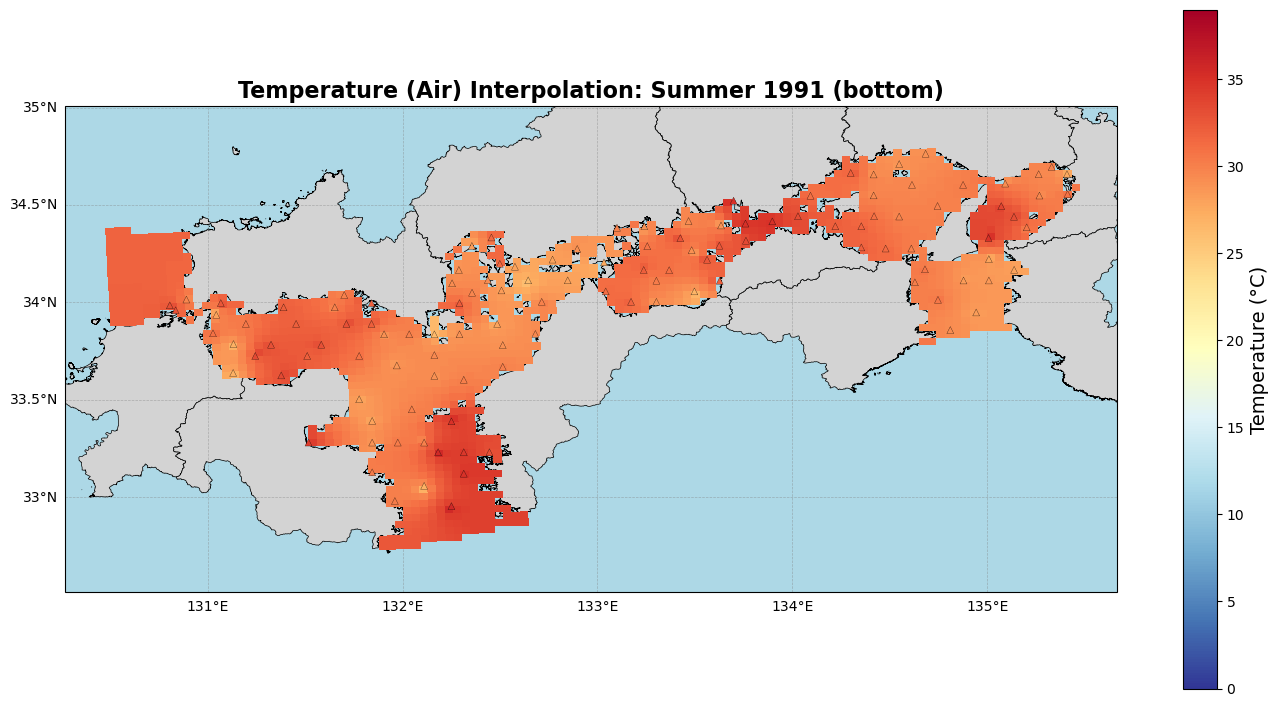

In [6]:
param_values = load_year_data(season, layer, target_year)

if param_values is not None and len(param_values) > 0:
    Z = run_diffusion_interpolation(param_values, stations_utm,
                                     grid_x_1d, grid_y_1d,
                                     water_mask, grid_x, grid_y)

    var_cfg = MappingConfig.get_var_settings(PARAMETER_CONFIG_KEY)
    vmin, vmax = var_cfg['vmin'], var_cfg['vmax']
    cmap = var_cfg['cmap']
    label = var_cfg['label']

    fig, ax = plt.subplots(1, 1, figsize=(14, 10),
                           subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Ocean Background
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    # Custom Coastal Boundaries (Land)
    add_land_to_ax(ax, land_patches_data)
    
    # Extent
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2,
                   bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())

    # Add Gridlines to match SIS Mapping Standard
    gl = ax.gridlines(draw_labels=True, 
                      linestyle=MappingConfig.GRID_LINESTYLE, 
                      color=MappingConfig.GRID_COLOR, 
                      alpha=MappingConfig.GRID_ALPHA, 
                      linewidth=MappingConfig.GRID_LINEWIDTH, 
                      zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False

    # Predicted Data Overlay
    c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z,
                        transform=ccrs.PlateCarree(),
                        cmap=cmap, shading='nearest',
                        zorder=MappingConfig.ZORDER_PREDICTED,
                        vmin=vmin, vmax=vmax)

    # Observation Data Overlay
    plot_df = param_values.join(stations_gdf, how='inner')
    ax.scatter(plot_df['longitude'], plot_df['latitude'],
               c=plot_df[PARAMETER], cmap=cmap,
               edgecolors='black', linewidth=0.2,
               transform=ccrs.PlateCarree(),
               zorder=MappingConfig.ZORDER_OBSERVATIONS,
               marker='^', s=25, vmin=vmin, vmax=vmax)

    cbar = fig.colorbar(c_m, ax=ax, shrink=0.7)
    cbar.set_label(label, fontsize=14)
    ax.set_title(f'{PARAMETER_DISPLAY_NAME} Interpolation: {season} {target_year} ({layer})',
                 fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
else:
    print(f'No data for {season} {target_year} ({layer})')

## 6. Four-Season Layout (2×2) for Target Year

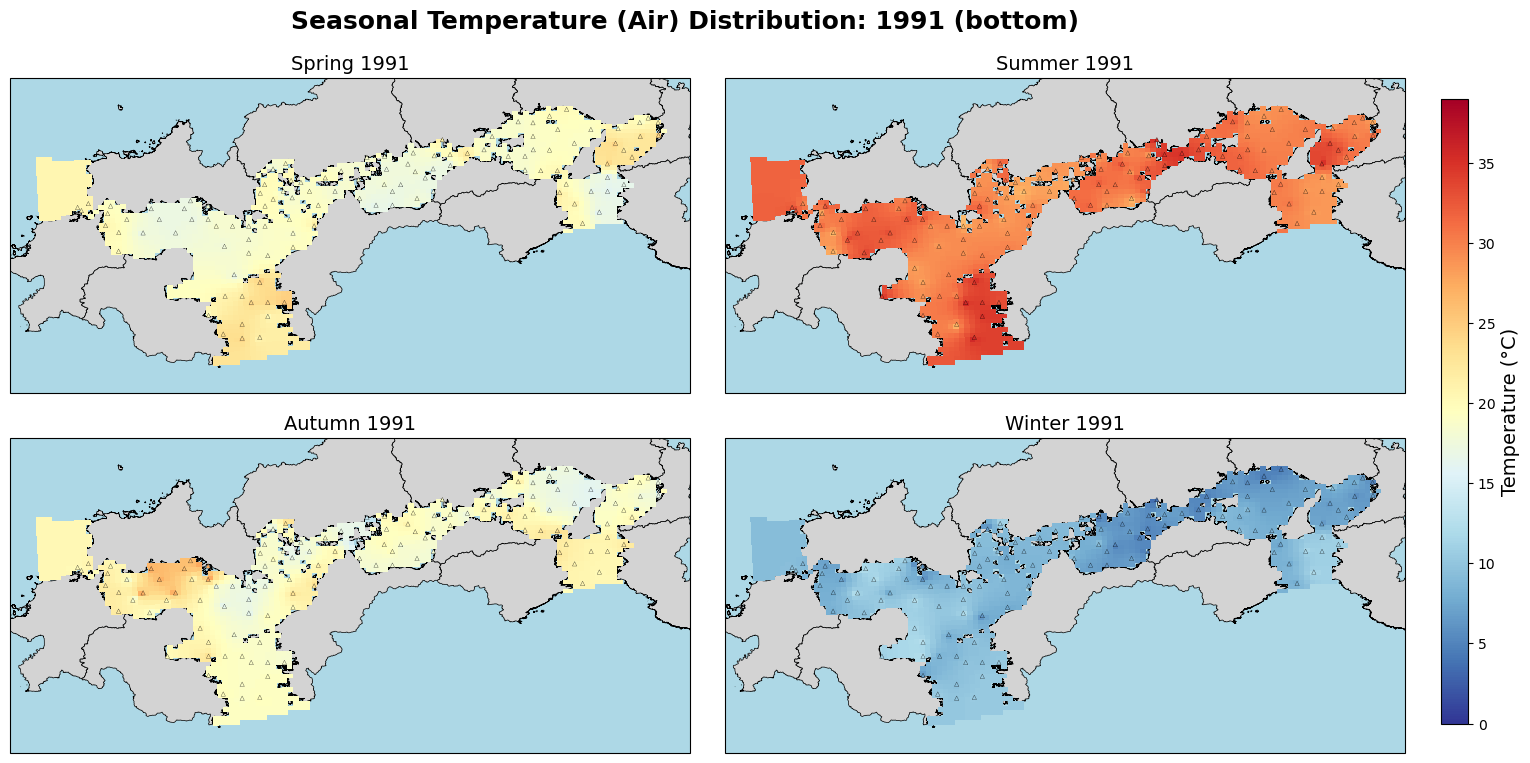

In [6]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
var_cfg = MappingConfig.get_var_settings(PARAMETER_CONFIG_KEY)
vmin, vmax = var_cfg['vmin'], var_cfg['vmax']
cmap = var_cfg['cmap']
label = var_cfg['label']

# Dynamically calculated height based on extent aspect ratio
extent = [bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2]
aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])

fig_width = 18
width_per_subplot = fig_width / 2
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.3
fig_height = height_per_subplot * 2

fig, axes = plt.subplots(2, 2, figsize=(fig_width, fig_height),
                          subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

for i, s in enumerate(seasons):
    ax = axes[i]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    add_land_to_ax(ax, land_patches_data)
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2,
                   bounds[1]-0.2, bounds[3]+0.2],
                  crs=ccrs.PlateCarree())

    param_values = load_year_data(s, layer, target_year)
    if param_values is not None and len(param_values) > 0:
        Z = run_diffusion_interpolation(param_values, stations_utm,
                                         grid_x_1d, grid_y_1d,
                                         water_mask, grid_x, grid_y)
        c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z,
                            transform=ccrs.PlateCarree(),
                            cmap=cmap, shading='nearest',
                            zorder=MappingConfig.ZORDER_PREDICTED,
                            vmin=vmin, vmax=vmax)

        plot_df = param_values.join(stations_gdf, how='inner')
        ax.scatter(plot_df['longitude'], plot_df['latitude'],
                   c=plot_df[PARAMETER], cmap=cmap,
                   edgecolors='black', linewidth=0.2,
                   transform=ccrs.PlateCarree(),
                   zorder=MappingConfig.ZORDER_OBSERVATIONS,
                   marker='^', s=10, vmin=vmin, vmax=vmax)

    ax.set_title(f'{s} {target_year}', fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

# Colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(c_m, cax=cbar_ax)
cbar.set_label(label, fontsize=14)
plt.suptitle(f'Seasonal {PARAMETER_DISPLAY_NAME} Distribution: {target_year} ({layer})',
             fontsize=18, fontweight='bold', y=0.95)
plt.subplots_adjust(right=0.9, wspace=0.05, hspace=0.1)
plt.show()

## 7. Progressive Seasonal Subplots (All Years)
All available years for each season, plotted in a grid.

--- Processing Spring ---
Interpolating 38 years...
Spring interpolation done in 0.74s
Total Spring cell time: 40.79s



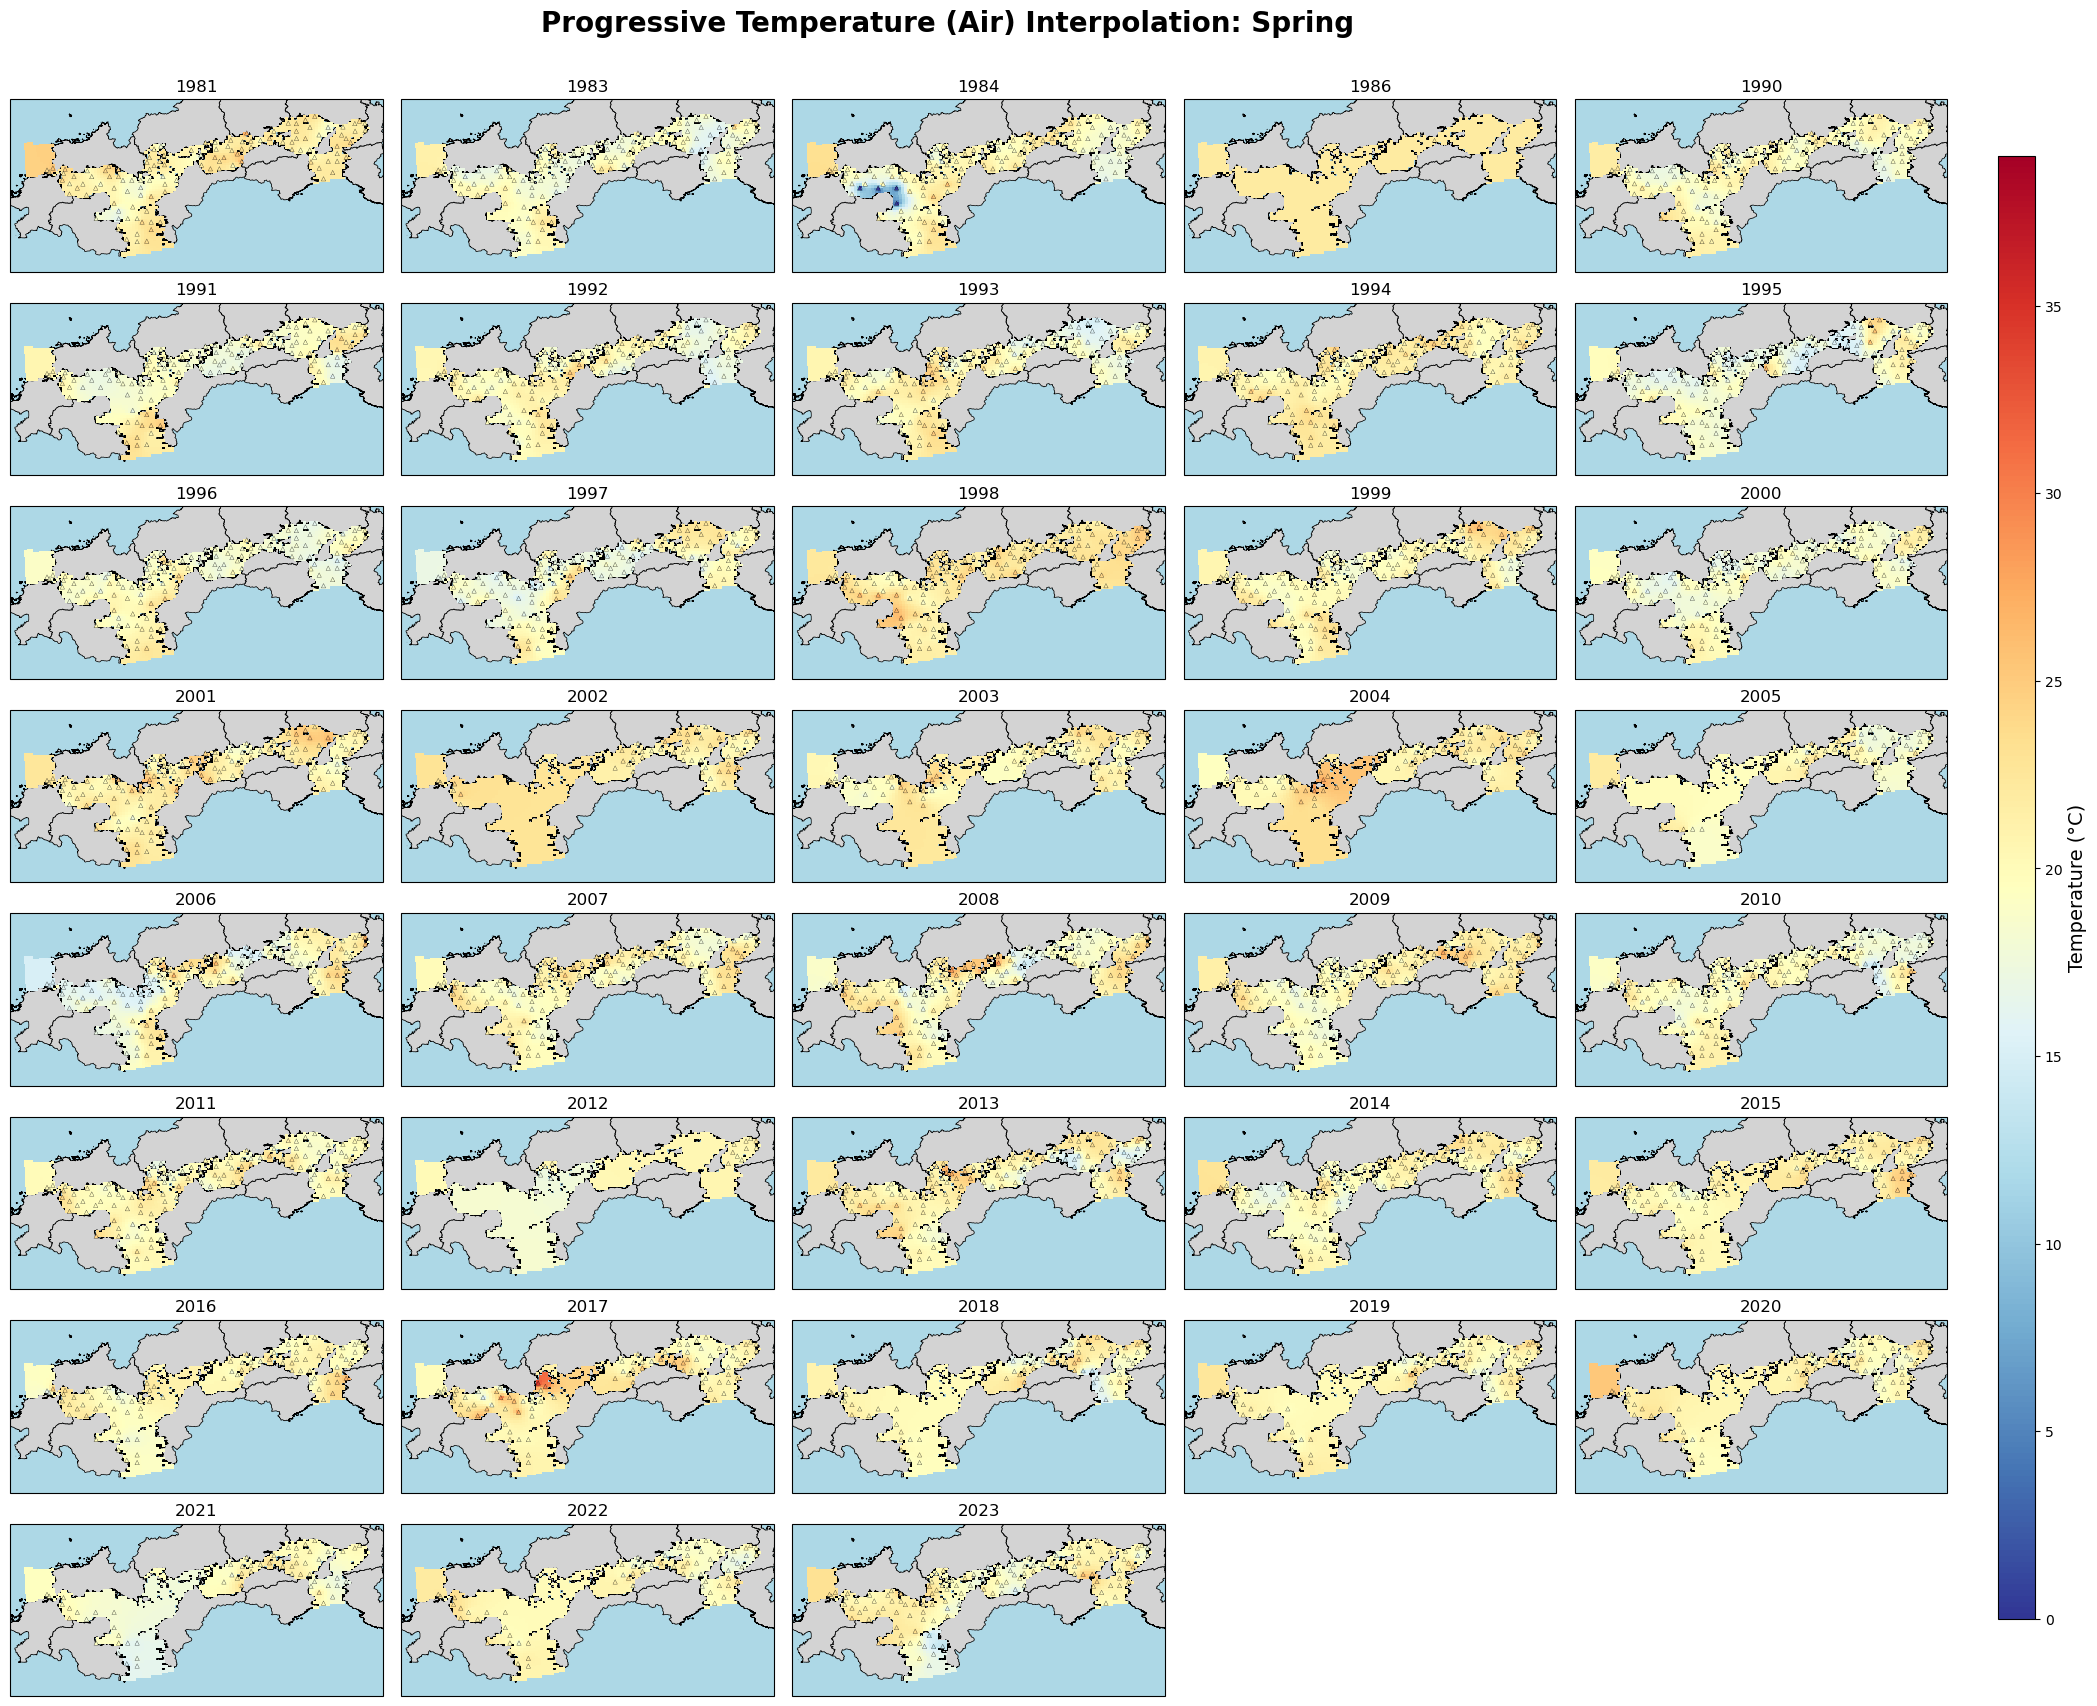

--- Processing Summer ---
Interpolating 36 years...
Summer interpolation done in 0.67s
Total Summer cell time: 45.85s



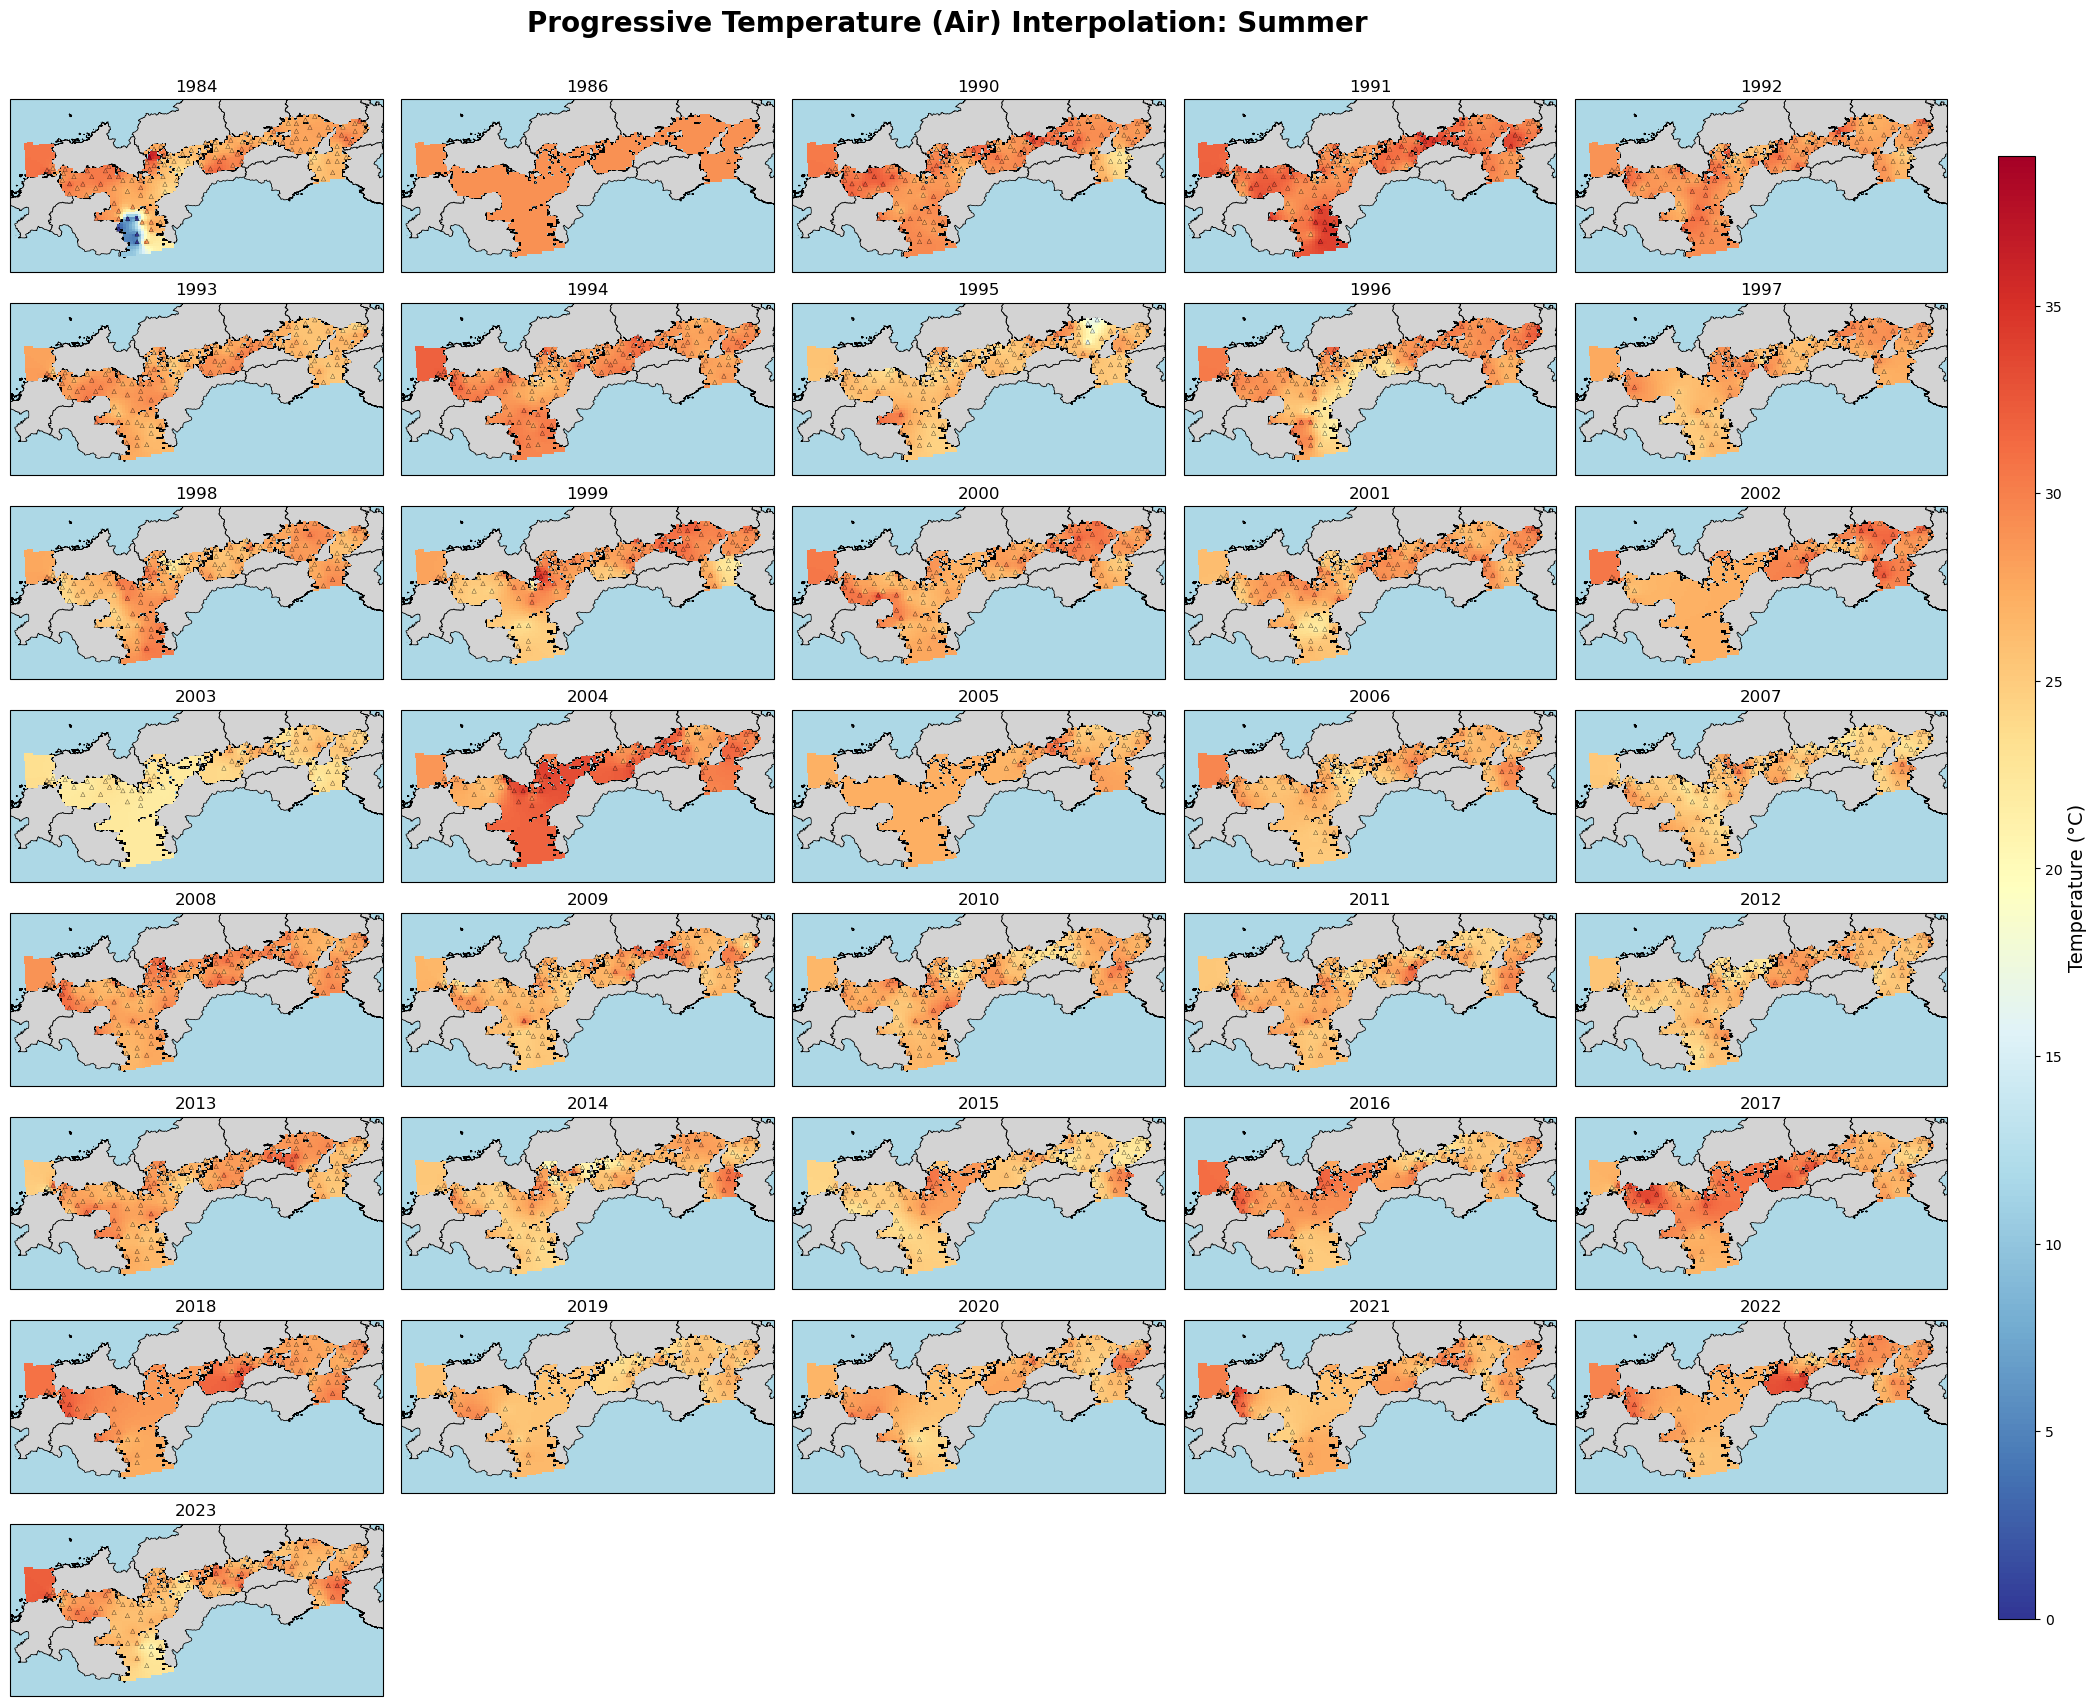

--- Processing Autumn ---
Interpolating 37 years...
Autumn interpolation done in 0.75s
Total Autumn cell time: 51.07s



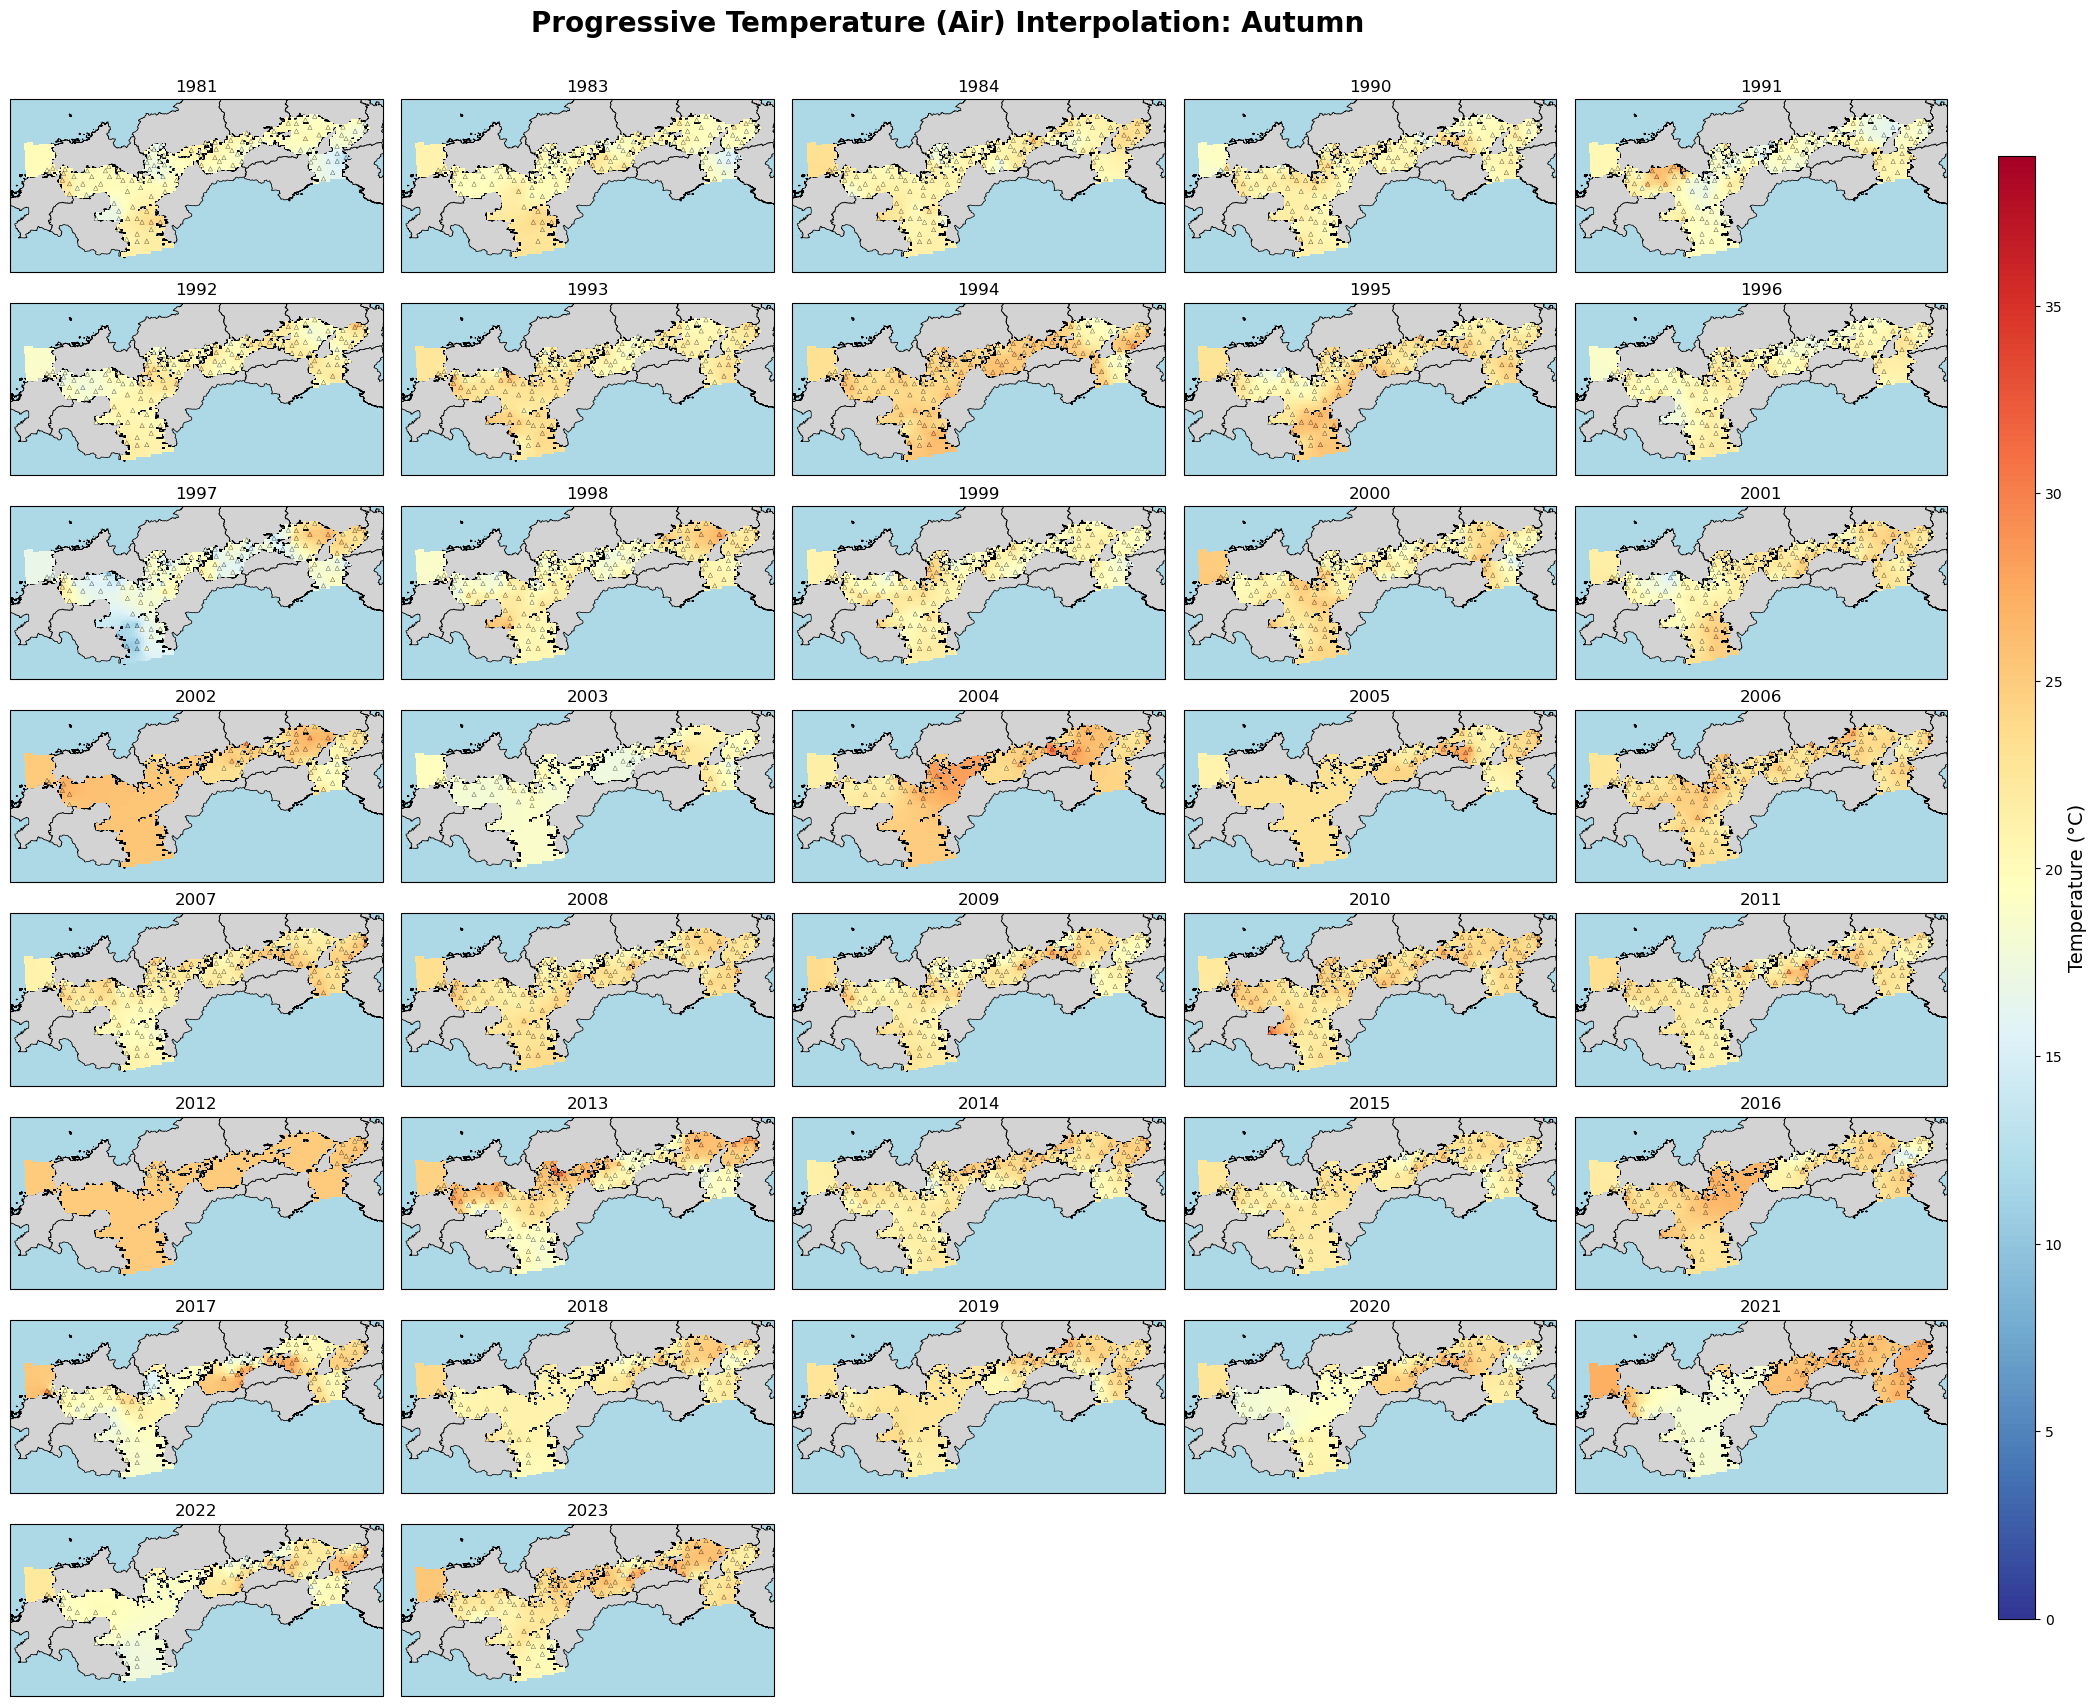

--- Processing Winter ---
Interpolating 38 years...
Winter interpolation done in 0.77s
Total Winter cell time: 60.68s



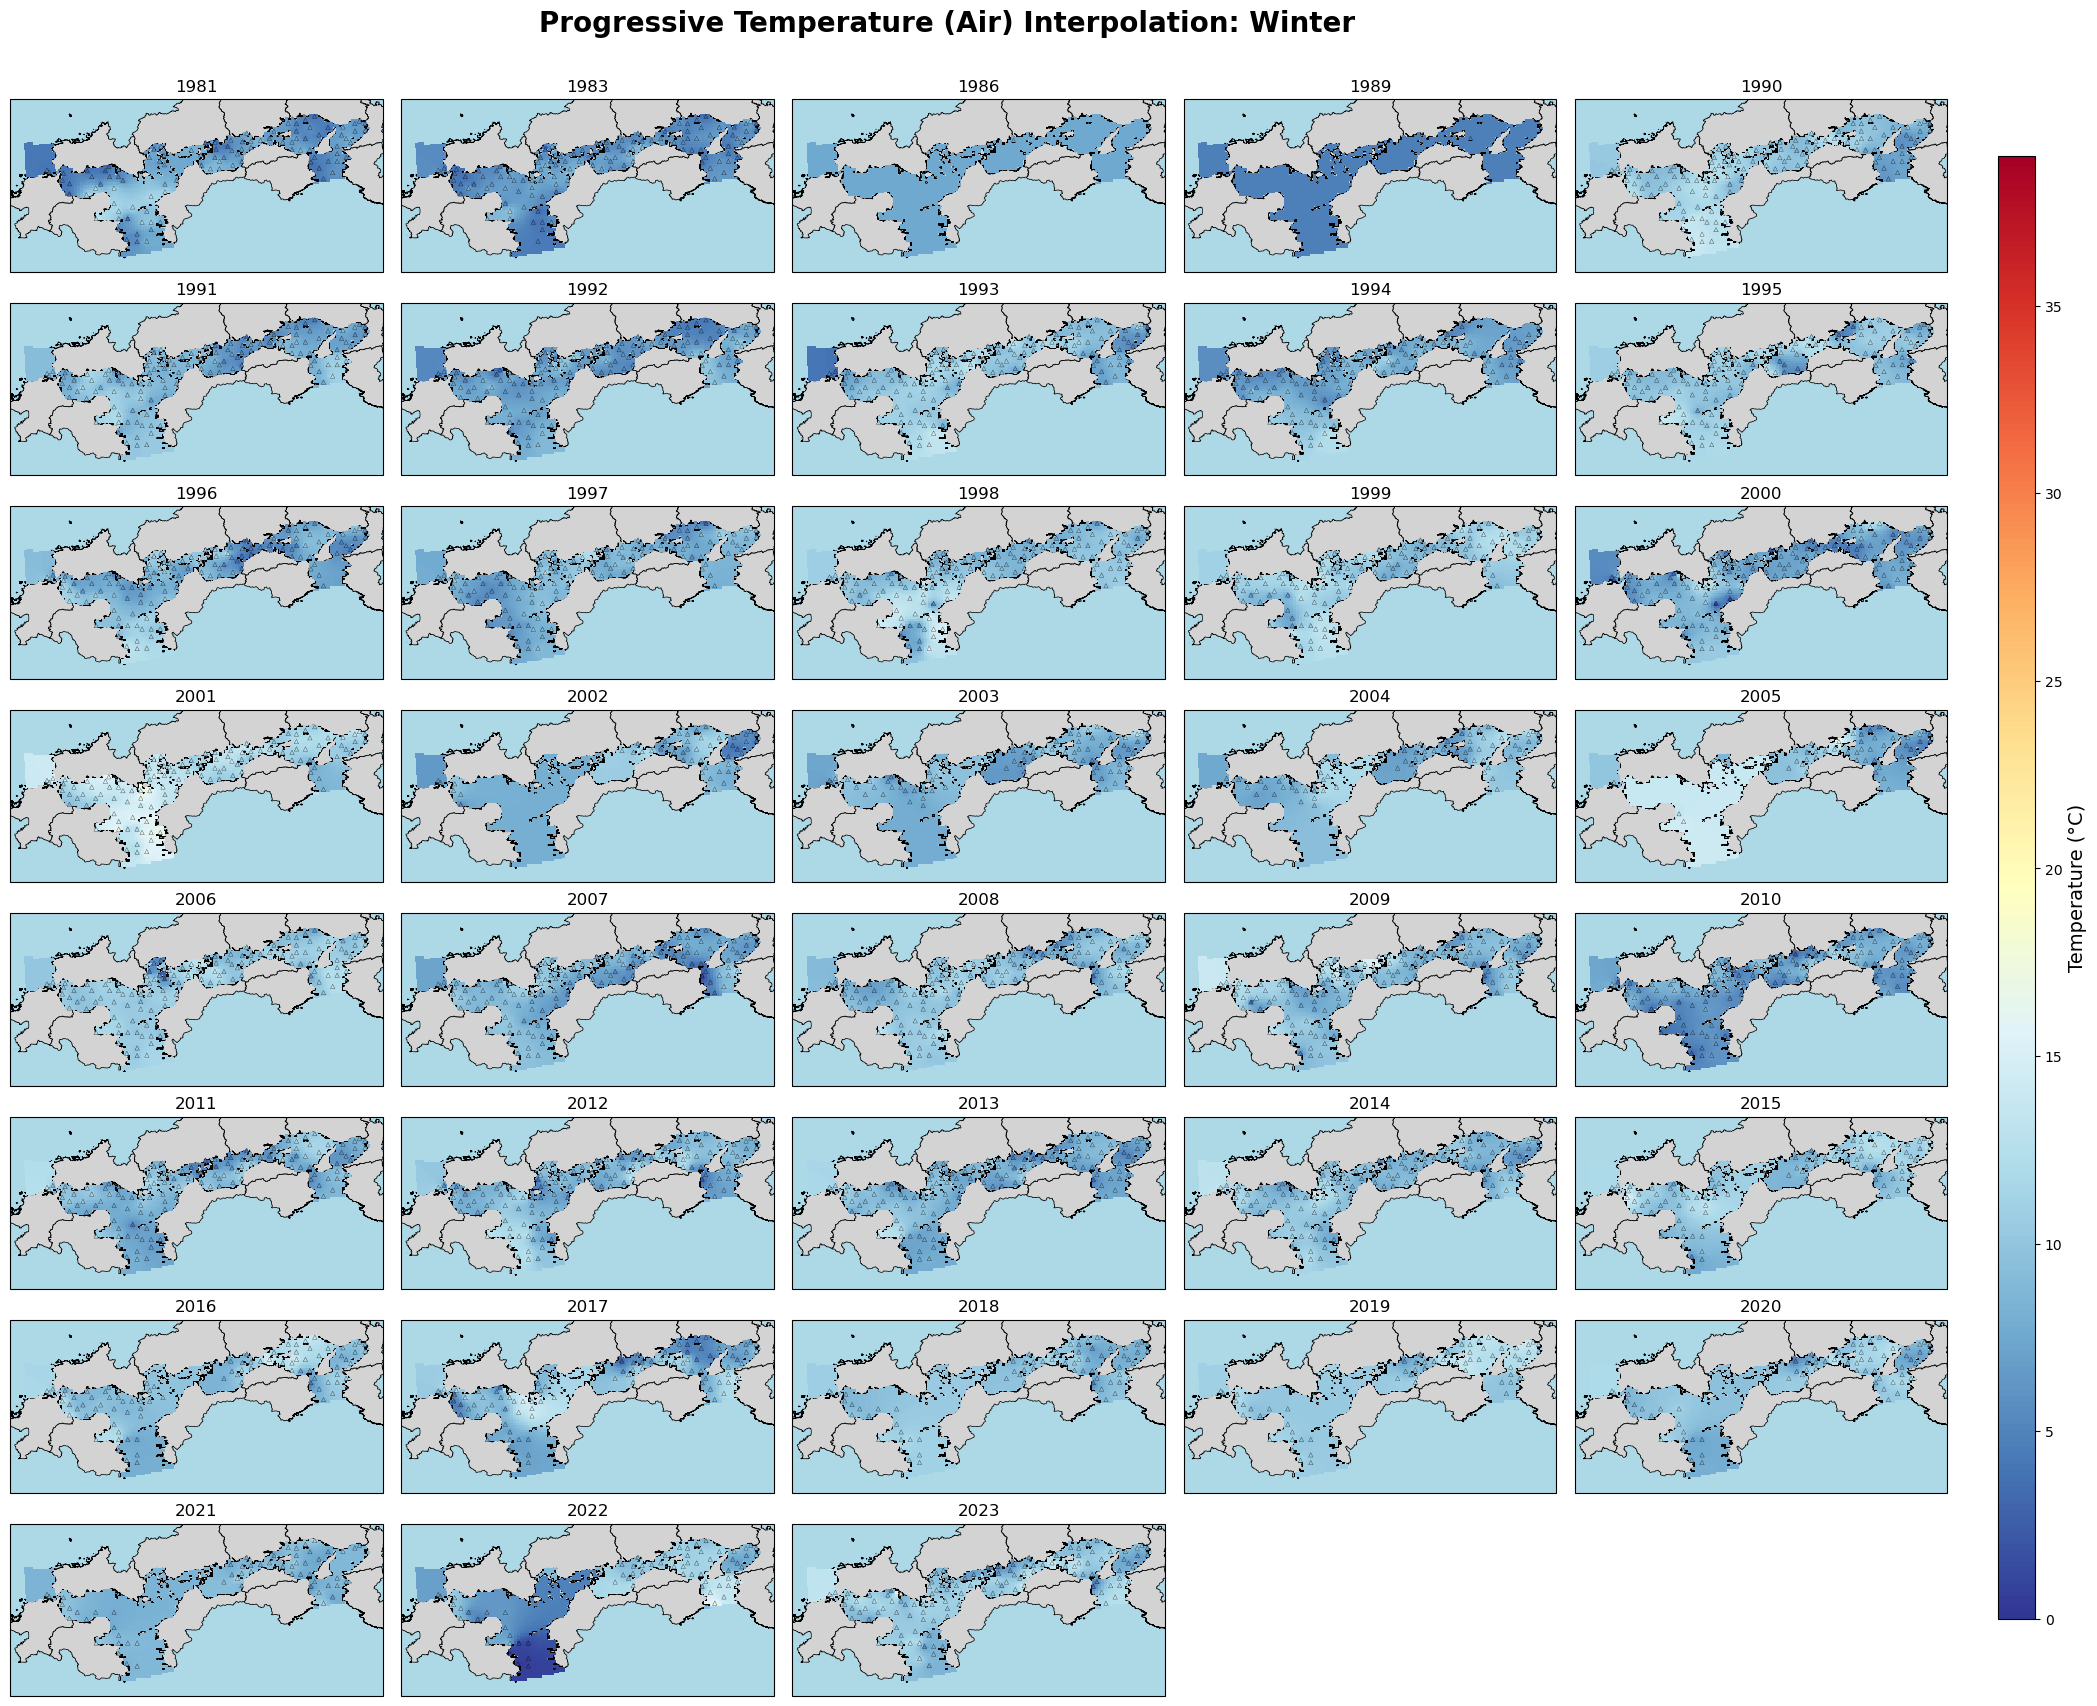

In [7]:
import time

seasons = ['Spring', 'Summer', 'Autumn', 'Winter']

for season in seasons:
    print(f"--- Processing {season} ---")
    t_start = time.time()
    
    # Load yearly data from pre-computed CSV
    subset_dir = ProjectPaths.get_subset_dir(season, layer)
    data_file_path = subset_dir / DATA_FILE
    
    if not data_file_path.exists():
        print(f"Data file not found for {season}. Skipping.\n")
        continue
        
    yearly_param_df = pd.read_csv(data_file_path, dtype={'zettaicode': str}).set_index('zettaicode')
    available_years = sorted([col for col in yearly_param_df.columns if str(col).isdigit()])
    n_years = len(available_years)
    print(f'Interpolating {n_years} years...')
    
    # --- Interpolation pass (the expensive part) ---
    all_Z = {}
    for y in available_years:
        param_values = yearly_param_df[[y]].dropna().rename(columns={y: PARAMETER})
        if len(param_values) > 0:
            all_Z[y] = run_diffusion_interpolation(
                param_values, stations_utm,
                grid_x_1d, grid_y_1d,
                water_mask, grid_x, grid_y)
    
    t_interp = time.time() - t_start
    print(f'{season} interpolation done in {t_interp:.2f}s')
    
    if n_years == 0:
        continue
        
    # --- Plotting pass ---
    var_cfg = MappingConfig.get_var_settings(PARAMETER_CONFIG_KEY)
    vmin, vmax = var_cfg['vmin'], var_cfg['vmax']
    cmap = var_cfg['cmap']
    label = var_cfg['label']
    
    n_cols = 5
    n_rows = int(np.ceil(n_years / n_cols))

    # Dynamically calculated height based on extent aspect ratio
    extent = [bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2]
    aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])

    fig_width = 25
    width_per_subplot = fig_width / n_cols
    height_per_subplot = (width_per_subplot * aspect_ratio) + 0.3
    fig_height = height_per_subplot * n_rows

    fig, axes = plt.subplots(n_rows, n_cols,
                            figsize=(fig_width, fig_height),
                            subplot_kw={'projection': ccrs.PlateCarree()})

    # Safely flatten axes
    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = [axes]
        
    c_m = None
    
    for i, y in enumerate(available_years):
        ax = axes[i]
        ax.set_facecolor(MappingConfig.COLOR_OCEAN)
        add_land_to_ax(ax, land_patches_data)
        ax.set_extent([bounds[0]-0.2, bounds[2]+0.2,
                       bounds[1]-0.2, bounds[3]+0.2],
                      crs=ccrs.PlateCarree())
    
        if y in all_Z:
            Z = all_Z[y]
            c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z,
                                transform=ccrs.PlateCarree(),
                                cmap=cmap, shading='nearest',
                                zorder=MappingConfig.ZORDER_PREDICTED,
                                vmin=vmin, vmax=vmax)
    
            param_values = yearly_param_df[[y]].dropna().rename(columns={y: PARAMETER})
            plot_df = param_values.join(stations_gdf, how='inner')
            ax.scatter(plot_df['longitude'], plot_df['latitude'],
                       c=plot_df[PARAMETER], cmap=cmap,
                       edgecolors='black', linewidth=0.2,
                       transform=ccrs.PlateCarree(),
                       zorder=MappingConfig.ZORDER_OBSERVATIONS,
                       marker='^', s=10, vmin=vmin, vmax=vmax)
    
        ax.set_title(f'{y}', fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Remove unused axes for the specific season's grid
    for j in range(len(available_years), len(axes)):
        fig.delaxes(axes[j])
    
    # Single colorbar per season figure
    if c_m is not None:
        cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
        cbar = fig.colorbar(c_m, cax=cbar_ax)
        cbar.set_label(label, fontsize=14)
    
    plt.suptitle(f'Progressive {PARAMETER_DISPLAY_NAME} Interpolation: {season}',
                 fontsize=20, fontweight='bold', y=0.92)
    plt.subplots_adjust(right=0.9, wspace=0.05, hspace=0.1)
    
    t_total = time.time() - t_start
    print(f'Total {season} cell time: {t_total:.2f}s\n')
    plt.show()